In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("Lab_4_data_fitting.ipynb")

# Lab week 4: Data fitting to see if we can detect a grasp success y/n

Can you use the finger 1 stop time and max value to tell the difference between a successful and a failed grasp?

Lab slides: https://docs.google.com/presentation/d/1NtoXYbl2nq1dkIU0KQE8ogjSCfb22wgLigY3JJpHHGI/edit?usp=sharing


In [2]:
# Doing the imports for you
import numpy as np
import json as json
from scipy.stats import linregress
import matplotlib.pyplot as plt
from numpy.polynomial import polynomial

## Read the data in 

In [3]:
# GUIDES: Read the same data in as for the lecture activity and put it in the data_motor_position variable and make
#   your ts values

time_step = 1/30


data_motor_position = np.loadtxt('Data/Motor position f1.csv', delimiter=',')  # Motor position f1.csv
ts = np.arange(0, 4/3, 1/30)

# 

In [4]:
grader.check("Read data")

Read data results: All test cases passed!

## Box plot of fitted lines for all data

In the lecture activity you fit a line to just one row (each) of the successful versus failed grasps. In this lab you'll fit the line to ALL of the grasps. For each grasp, save the end point (time at the **y_max** value and the **y_max** value and the error of the fit). You'll be making a box plot of this data to see if either look different for successful versus failed grasps.

Why a box plot? Box plots are better for visually showing multiple distributions in the same plot, where they can be compared side-by-side.

See lab slides for what this should look like when you're done.

In [5]:
# GUIDES: Copy over fit_line_to_middle from the lecture activity
def fit_line_to_middle_bit(ts, ys, eps=1e-2):
    """ Fit a line to the sloped middle bit of the data
      Return the line as a pair of points, one where the fitted line crosses the y min value, one where the line crosses
      the y max value (see slides for picture)
    @param ts - the time values for the data (x-axis)
    @param ys - the function values (y-axis)
    @param eps - a fudge factor for clipping the middle bit (min + eps and max - eps)
    @returns (x_min, y_min), (x_max, y_max), std_err  (two tuples and the error of the fit)"""
    
    y_min = np.min(ys)
    y_max = np.max(ys)

    y_is_above_min = ys > y_min + eps * (y_max - y_min)
    y_is_below_max = ys < y_max - eps * (y_max - y_min)
    y_is_both = y_is_above_min & y_is_below_max
    y_is_where = np.where(y_is_both)

    y_is_where_indices = y_is_where[0]
    clipped_xs = ts[y_is_where_indices]
    clipped_ys = ys[y_is_where_indices]
    clipped_reg = linregress(clipped_xs, clipped_ys)

    x_min = (y_min - clipped_reg.intercept) / clipped_reg.slope
    x_max = (y_max - clipped_reg.intercept) / clipped_reg.slope
    err_fit = clipped_reg.stderr

    return (x_min, y_min), (x_max, y_max), err_fit


In [6]:
# TEST CELL
# GUIDES: Check that it works

#for i, row in enumerate(data_motor_position):
#        fit_line = fit_line_to_middle_bit(ts, row)
#        if math.isnan(fit_line[2]):
#                print(f"Error: sterr in row {i} is not a rumber. In row {i}, y_max = {fit_line[1][1]} & y_min = {fit_line[0][1]}")
#                data_points_where = np.where(((fit_line[0][1]) < row) & (row < (fit_line[1][1])))
#                usable_data_indices = data_points_where[0]
#                print(f"Number of usable data points in row {i} is {usable_data_indices.size}")
#                print("usable data includes:")
#                print(row[usable_data_indices])
#                print("")
#                print(row)
#                print("")
#        else:
#                pass

In [7]:
# EXAMPLE CODE
# This bit of code shows how to do the nx2 array part

# Make the nx2 array - one row for each element
np_array_for_res = np.zeros((data_motor_position.shape[0], 2))
# For each row
for row in range(0, data_motor_position.shape[0]):
    # Put the min value in the first column, the max in the second
    np_array_for_res[row, 0] = np.min(data_motor_position[row, :])    
    np_array_for_res[row, 1] = np.max(data_motor_position[row, :])

    # This also works
    min_value = np.min(data_motor_position[row, :]) 
    max_value = np.max(data_motor_position[row, :])
    np_array_for_res[row, :] = [min_value, max_value]

print(np_array_for_res.shape)

(660, 2)


In [8]:
def fit_middle_all(ts, data):
    """ Fit the middle for every row of data
    @param ts - the t values to use
    @param data - n picks X timesteps
    @returns all end times, max values, and errors as one numpy array (n rows X 3)"""

    final_np_array = np.zeros((data.shape[0], 3))
    for i, row in enumerate(data):
        np_array_info = fit_line_to_middle_bit(ts, row)
        final_np_array[i, 0] = np_array_info[1][0]
        final_np_array[i, 1] = np_array_info[1][1]
        if np.isnan(np_array_info[2]) or np.isinf(np_array_info[2]):
            print(f"Error: Either inf or nan value in row {i}. Row has been removed from data returned by fit_middle_all function")
            continue
        else:
            final_np_array[i, 2] = np_array_info[2]
        
    return final_np_array

In [9]:
# TEST CELL
# Write the code to call the function here

# The successful rows go from 0 to 354
last_row_successful = 355

# The unsuccessful rows are the remaining ones


# GUIDES:
#. Call your function twice, once with the successful data, once with the failed
fit_data_successful = fit_middle_all(ts, data_motor_position[0:last_row_successful, :])
fit_data_failed = fit_middle_all(ts, data_motor_position[last_row_successful:, :])

# Note for both of these: Small changes in how you index can result in slightly different numbers,
#  but the overall magnitude should be correct

# Note: Doing np.mean(nx3 array, 0) tells numpy to do the mean over each column (instead of the mean
#  over the entire nx3 array). So it should return 3 numbers - the mean of the times, the mean
#  of the max y values, and the mean of the fit error

# Should print the following, although the actual decimal places may differ
#  Mean successful [3.98791579e-01 4.07402569e+02 4.21582062e+00] and failed [  0.40810473 392.76044707   5.51566179]
print(f"Mean successful {np.mean(fit_data_successful, 0)} and failed {np.mean(fit_data_failed, 0)}")

Error: Either inf or nan value in row 14. Row has been removed from data returned by fit_middle_all function
Error: Either inf or nan value in row 199. Row has been removed from data returned by fit_middle_all function
Error: Either inf or nan value in row 320. Row has been removed from data returned by fit_middle_all function
Mean successful [3.98791579e-01 4.07402569e+02 4.21582062e+00] and failed [  0.40810473 392.76044707   5.51566179]


In [10]:
grader.check("Fitted_line_code")

Fitted_line_code results: All test cases passed!

<!-- BEGIN QUESTION -->

## Do the box plots

- Left window: t values of y_max point (the first column of fit_data_*)

- Middle window: y_max values (the second column of fit_data_*)

- Right window: fit error values (the third column of fit_data_*)

Note that boxplot uses labels for labeling the x axis of the box plot.

Implementation order: for plotting, try calling box plot with just one column of data. Then add the second. 

Text(0.5, 1.0, 'Fit err')

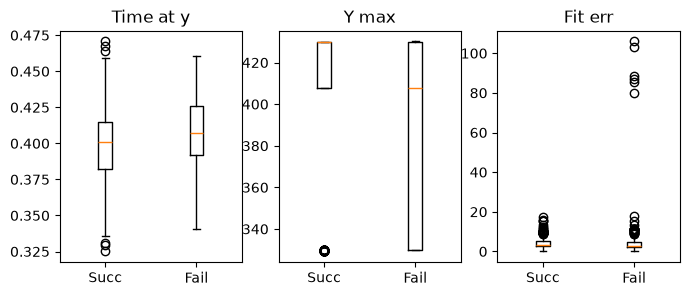

In [11]:
# Three plots
n_rows = 1
n_cols = 3
fig, axs = plt.subplots(n_rows, n_cols, figsize=(8, 3))

axs[0].boxplot((fit_data_successful[:, 0], fit_data_failed[:, 0]), tick_labels=('Succ', 'Fail'))
axs[0].set_title("Time at y")

axs[1].boxplot((fit_data_successful[:, 1], fit_data_failed[:, 1]), tick_labels=('Succ', 'Fail'))
axs[1].set_title("Y max")

axs[2].boxplot((fit_data_successful[:, 2], fit_data_failed[:, 2]), tick_labels=('Succ', 'Fail'))
axs[2].set_title("Fit err")

# Do the box plots...

In [12]:
# Manual grade
print("This is a manually-graded question; there is no grader.check() function. See rubric and slides for more information on expected output.")

This is a manually-graded question; there is no grader.check() function. See rubric and slides for more information on expected output.


<!-- END QUESTION -->

# Part 2: Fitting a curve to the wrist force data

## First step: Getting the data

Along with the motor data we also have force data at the wrist. The wrist force data has three channels (x,y,z). For this assignment, we want to get out the total magnitude of the force at the wrist, rather than the force in each direction individually:

Equation: **sqrt (sum x,y,z (wrist force data)^2)**

The data is stored in **Wrist_force_data.csv** in the Data directory. 

In [13]:

# GUIDES: Read in the data; should be 660 x 120 (x,y,z data for 40 time steps)
data_wrist_force_xyz = np.loadtxt('Data/Wrist_force_data.csv', delimiter=',')
assert data_wrist_force_xyz.shape == (660, 120)

In [14]:
# GUIDES: Calculate the total force (see equation above)

# GUIDES: Calculate the magnitude of the force

data_wrist_force_magnitude = np.sqrt((data_wrist_force_xyz[:, 0::3]**2) + (data_wrist_force_xyz[:, 1::3]**2) + (data_wrist_force_xyz[:, 2::3]**2))

assert data_wrist_force_magnitude.shape == (660, 40)
assert np.isclose(data_wrist_force_magnitude[0, 0], 6.5389367, atol=0.001)
assert np.isclose(np.max(data_wrist_force_magnitude), 20.46059305836466, atol=0.001)

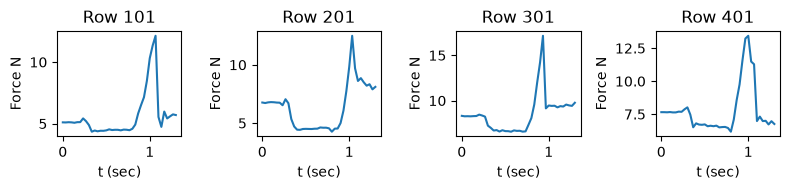

In [15]:
# Plot a few of the rows to see what the data looks like
n_rows = 1
n_cols = 4
fig, axs = plt.subplots(n_rows, n_cols, figsize=(8, 2))

# GUIDES: Pick 4 examples to plot. Use your ts values from above. You do not need to
#   use the ones from the slides, but you should but the example number in the title
# Don't forget to label the x and y axes

axs[0].plot(ts, data_wrist_force_magnitude[101, :])
axs[0].set_title('Row 101')
axs[0].set_xlabel('t (sec)')
axs[0].set_ylabel('Force N')

axs[1].plot(ts, data_wrist_force_magnitude[201, :])
axs[1].set_title('Row 201')
axs[1].set_xlabel('t (sec)')
axs[1].set_ylabel('Force N')

axs[2].plot(ts, data_wrist_force_magnitude[301, :])
axs[2].set_title('Row 301')
axs[2].set_xlabel('t (sec)')
axs[2].set_ylabel('Force N')

axs[3].plot(ts, data_wrist_force_magnitude[401, :])
axs[3].set_title('Row 401')
axs[3].set_xlabel('t (sec)')
axs[3].set_ylabel('Force N')

plt.tight_layout()

In [16]:
grader.check("Fit_curve")

Fit_curve results: All test cases passed!

## Write a function to fit a polynomial to one row of the data

Since we aren't sure what a "good" polynomial fit might be, make that a parameter

In [17]:
def fit_poly(ts, data, deg):
    """ Fit a polynomial to the data
    @param ts - the x values
    @param data - the y values
    @param degree of the polynomial. Should be an integer
    @return a list of polynomial coefficients (see polynomial.polyfit)"""
    
    ret_poly = polynomial.polyfit(ts, data, deg) # Call polynomial.polyfit
    return ret_poly



In [18]:
# Test

check_poly = fit_poly(ts, data_wrist_force_magnitude[10], deg=2)


assert np.all(np.isclose(check_poly, [10.0970104, -13.91458045, 10.73089215], atol=0.01))

In [19]:
grader.check("fit_cubic")

fit_cubic results: All test cases passed!

<!-- BEGIN QUESTION -->

## Check the fit

It's not always clear what a "good" fit is. In this part of the code we'll plot a rset of examples, with increasing degrees of polynomials.

Sometimes you just want to plot some examples but don't really care which ones; this problem also has a solution to the "I have space for n plots, I want to skip over some of the data" problem

In [20]:
# EXAMPLE CODE - row column indexing, how to put n things into a grid

# If you have n things, and you want to put them in r rows, first figure out how many columns you'll need
#  Integer division: 
#    n // r  gives the number of times r can go into n
#    n % r gives the left over - it is always in the range 0 to n-1
n = 15
r = 4
c = n // r  # this gives the floor of n / r, which in this case will be 15/4 is 3
if n % r != 0:  # % is modulus - unless r goes exactly into n we need to add a bit (some of the last columns will be empty)
    c += 1   # Make c one bigger

# Go through all of n
for i in range(0, n):
    row = i // r   # Which row we're on
    col = i % r    # Which column we're on
    end_str = " "       # Use a space at the end of the pring
    if col == r-1:
        end_str = "\n"  # ... except at the end of the row
    print(f"n{i}r{row}c{col} ", end=end_str)  # No return


n0r0c0  n1r0c1  n2r0c2  n3r0c3 
n4r1c0  n5r1c1  n6r1c2  n7r1c3 
n8r2c0  n9r2c1  n10r2c2  n11r2c3 
n12r3c0  n13r3c1  n14r3c2  

In [21]:
# EXAMPLE CODE - zip
# These two pieces of code do the same thing
a_str = ("foo", "bar")
b_number = (3, 10)
for i in range(len(a_str)):
    a = a_str[i]
    b = b_number[i]
    print(f"Loop iteration {i} has {a} and {b}")

# Look, no i!
for a, b in zip(a_str, b_number):
    print(f"Loop iteration... um... has {a} and {b}")

Loop iteration 0 has foo and 3
Loop iteration 1 has bar and 10
Loop iteration... um... has foo and 3
Loop iteration... um... has bar and 10


In [22]:
# SCRATCH CELL
# Practice the plot for one row of data

#color_deg = ("maroon", "steelblue", "olivedrab")
#deg_fit = (1, 3, 6)
#lstyle = ('dashed', 'dotted', 'dashdot')
#labels = ('Deg 1', 'Deg 3', 'Deg 6')

#n_rows = 1
#n_cols = 1
#fig, axs = plt.subplots(n_rows, n_cols, figsize=(3, 3))

#axs.plot(ts, data_wrist_force_magnitude[101, :], color='black', label="Data")
#axs.plot(ts, polynomial.polyval(ts, fit_poly(ts, data_wrist_force_magnitude[101, :], deg_fit[0])), color=color_deg[0], label=labels[0], linestyle=lstyle[0])
#axs.plot(ts, polynomial.polyval(ts, fit_poly(ts, data_wrist_force_magnitude[101, :], deg_fit[1])), color=color_deg[1], label=labels[1], linestyle=lstyle[1])
#axs.plot(ts, polynomial.polyval(ts, fit_poly(ts, data_wrist_force_magnitude[101, :], deg_fit[2])), color=color_deg[2], label=labels[2], linestyle=lstyle[2])
#axs.set_title('Row 101')
#axs.set_xlabel('time (s)')
#axs.set_ylabel('N.m')
#axs.legend()

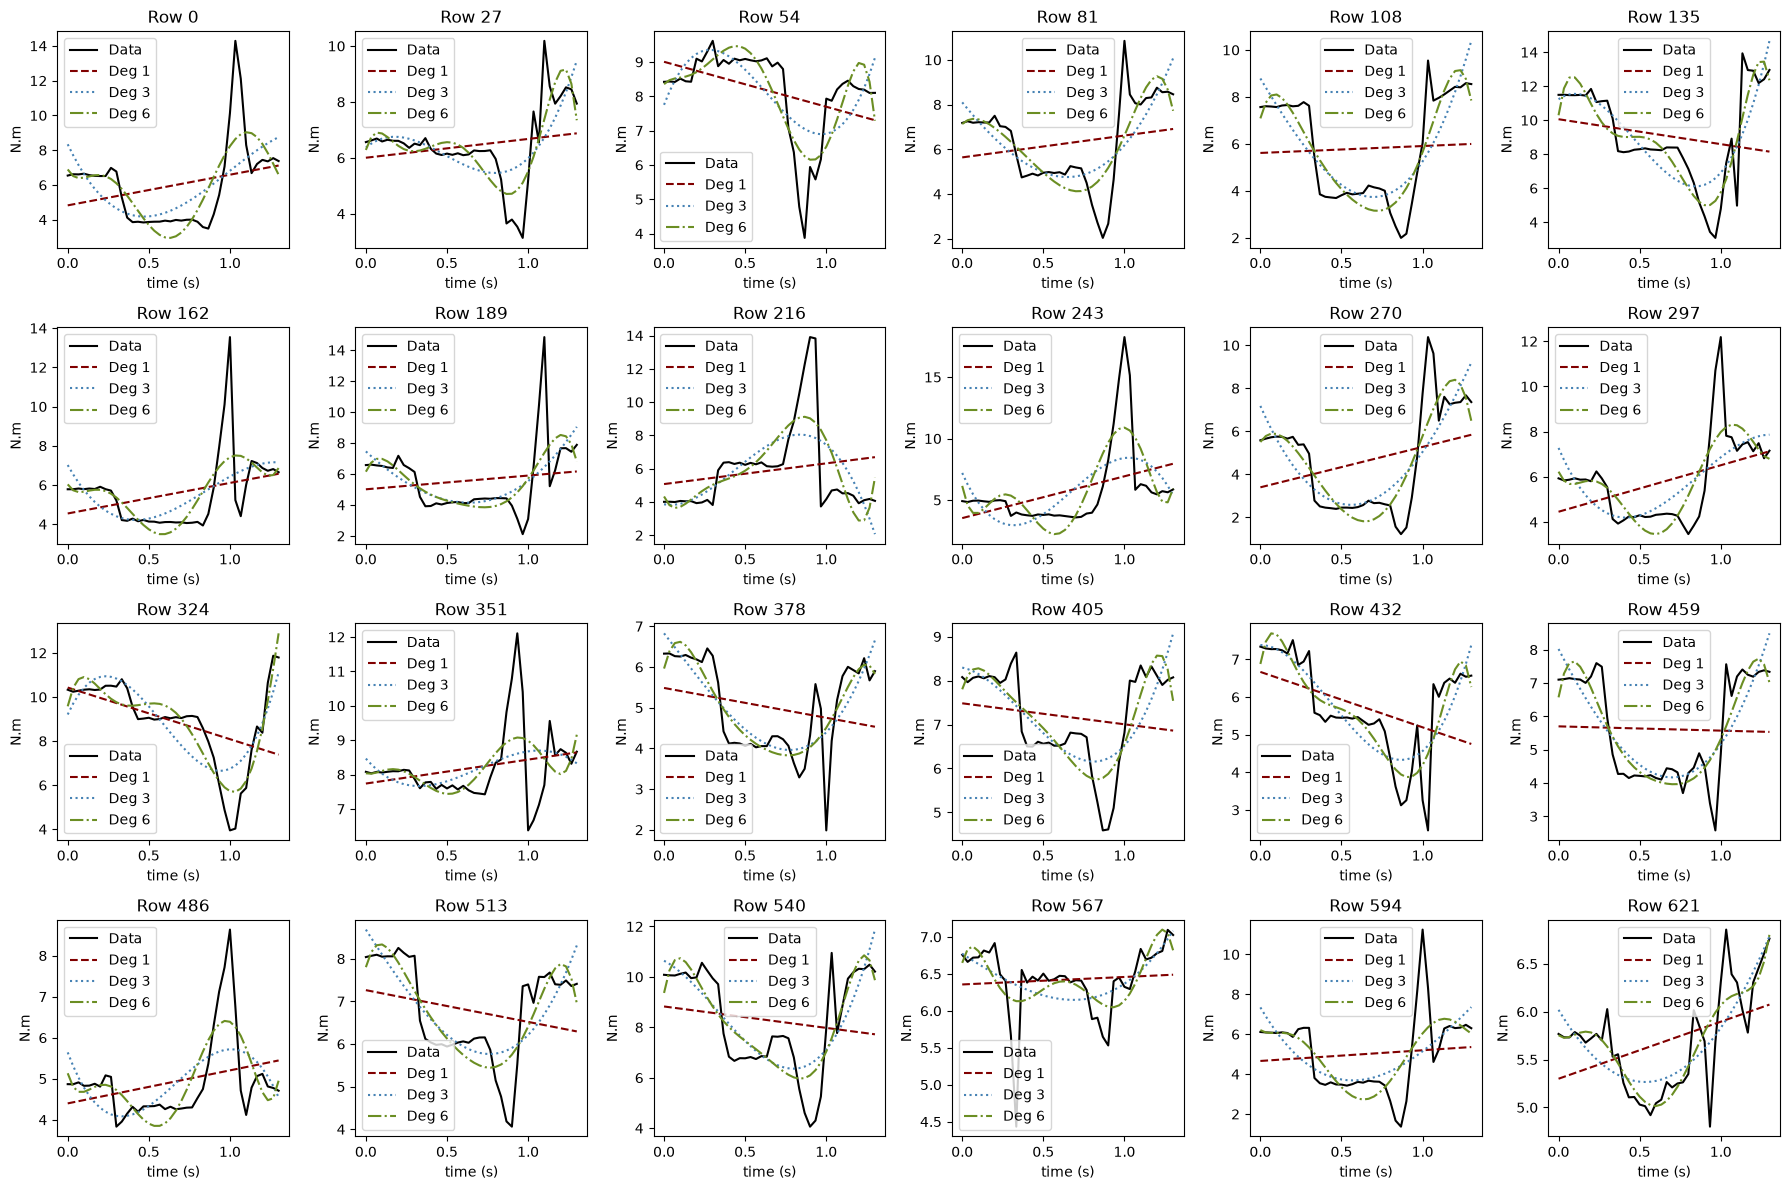

In [23]:
# Note: This code will all work even if you change the number of rows/columns
n_rows = 4
n_cols = 6
fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))

n_total_plots = n_rows * n_cols
# take every nth
n_skip = data_wrist_force_magnitude.shape[0] // n_total_plots

color_deg = ("maroon", "steelblue", "olivedrab")
deg_fit = (1, 3, 6)
lstyle = ('dashed', 'dotted', 'dashdot')
labels = ('Deg 1', 'Deg 3', 'Deg 6')
# This loops over the total number of plots we can fit
for i in range(0, n_total_plots):
    # Yes, this works - it's the same as doing r = row_offset + p // ncols on one line,
    #   and c = p % n_cols on the second line
    r, c = i // n_cols, i % n_cols
    data_row_indx = i * n_skip

    # Plot 4 things in this figure:
    #   the original data (in black)
    #   polynomial fits of degree 1, 3, 6
    # Note: use axs[r, c]
    # Note 2: The data row you want is in data_row_indx...
    # Note 3: Use polynomial.polyval(ts, ret_poly) to create y values for your t values
    axs[r, c].plot(ts, data_wrist_force_magnitude[data_row_indx, :], color='black', label="Data")
    axs[r, c].plot(ts, polynomial.polyval(ts, fit_poly(ts, data_wrist_force_magnitude[data_row_indx, :], deg_fit[0])), color=color_deg[0], label=labels[0], linestyle=lstyle[0])
    axs[r, c].plot(ts, polynomial.polyval(ts, fit_poly(ts, data_wrist_force_magnitude[data_row_indx, :], deg_fit[1])), color=color_deg[1], label=labels[1], linestyle=lstyle[1])
    axs[r, c].plot(ts, polynomial.polyval(ts, fit_poly(ts, data_wrist_force_magnitude[data_row_indx, :], deg_fit[2])), color=color_deg[2], label=labels[2], linestyle=lstyle[2])
    axs[r, c].set_title(f"Row {data_row_indx}")
    axs[r, c].set_xlabel('time (s)')
    axs[r, c].set_ylabel('N.m')
    axs[r, c].legend()

plt.tight_layout()

In [24]:
# Manual grade
print("This is a manually-graded question; there is no grader.check() function. See rubric and slides for more information on expected output.")

This is a manually-graded question; there is no grader.check() function. See rubric and slides for more information on expected output.


<!-- END QUESTION -->

## Hours and collaborators
Required for every assignment - fill out before you hand-in.

Listing names and websites helps you to document who you worked with and what internet help you received in the case of any plagiarism issues. You should list names of anyone (in class or not) who has substantially helped you with an assignment - or anyone you have *helped*. You do not need to list TAs.

Listing hours helps us track if the assignments are too long.

In [25]:
import os

# List of names (creates a set)
worked_with_names = {"By Myself"}
# List of URLS FA26 (creates a set)
websites = {"https://www.w3schools.com/python/ref_func_enumerate.asp",
            "https://numpy.org/devdocs/reference/generated/numpy.isnan.html"
            "https://numpy.org/devdocs/reference/generated/numpy.isinf.html"
            "https://matplotlib.org/stable/plot_types/stats/boxplot_plot.html#sphx-glr-plot-types-stats-boxplot-plot-py"}
# Approximate number of hours, including lab/in-class time
hours = 12

# VS Code stores the path in a special global variable
if '__vsc_ipynb_file__' in globals():
    notebook_path = globals()['__vsc_ipynb_file__']
    notebook_name = os.path.basename(notebook_path)
    json_name = notebook_name[:-6] + "_source.json"
    if not os.path.exists(json_name):
        print(f"Could not find the json file {json_name}; make sure the required VSCode extension is installed and running")


In [26]:
grader.check("hours_collaborators")

hours_collaborators results: All test cases passed!

### To submit

- Do a restart then run all to make sure everything runs ok and the plots are showing
- Save the file
- Submit this .ipynb file, along with the .json file, through gradescope, Lab 4, fitting
- You do NOT need to submit the data files - we will supply those
- Where there are given variable/file names (eg, foo = ...) DON'T change those, or the autograder will fail

If the Gradescope autograder fails, please check here first for common reasons for it to fail
    https://docs.google.com/presentation/d/1tYa5oycUiG4YhXUq5vHvPOpWJ4k_xUPp2rUNIL7Q9RI/edit?usp=sharing

Most likely failure for this assignment is not naming the data directory and files correctly; capitalization matters for the Gradescope grader. 

A gentle reminder that you should NOT be copying and pasting code (let alone sending files) to other people in the class.